In [100]:
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report,confusion_matrix, roc_curve, roc_auc_score,precision_score
from sklearn.tree import DecisionTreeClassifier

In [2]:
claimants_data = pd.read_csv("Claimants.csv")

## Data understanding

In [3]:
claimants_data.shape

(1340, 7)

In [4]:
claimants_data.describe()

,CASENUM,ATTORNEY,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
count,1340.000000,1340.000000,1328.000000,1299.000000,1292.000000,1151.000000,1340.000000
mean,11202.001493,0.488806,0.558735,0.907621,0.017028,28.414422,3.806307
std,9512.750796,0.500061,0.496725,0.289671,0.129425,20.304451,10.636903
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,4177.000000,0.000000,0.000000,1.000000,0.000000,9.000000,0.400000
50%,8756.500000,0.000000,1.000000,1.000000,0.000000,30.000000,1.069500
75%,15702.500000,1.000000,1.000000,1.000000,0.000000,43.000000,3.781500
max,34153.000000,1.000000,1.000000,1.000000,1.000000,95.000000,173.604000


In [5]:
claimants_data

,CASENUM,ATTORNEY,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
0,5,0,0.0,1.0,0.0,50.0,34.940
1,3,1,1.0,0.0,0.0,18.0,0.891
2,66,1,0.0,1.0,0.0,5.0,0.330
3,70,0,0.0,1.0,1.0,31.0,0.037
4,96,1,0.0,1.0,0.0,30.0,0.038
...,...,...,...,...,...,...,...
1335,34100,1,0.0,1.0,0.0,NaN,0.576
1336,34110,0,1.0,1.0,0.0,46.0,3.705
1337,34113,1,1.0,1.0,0.0,39.0,0.099
1338,34145,0,1.0,0.0,0.0,8.0,3.177


In [6]:
claimants_data.isna().sum()

CASENUM       0
ATTORNEY      0
CLMSEX       12
CLMINSUR     41
SEATBELT     48
CLMAGE      189
LOSS          0
dtype: int64

In [7]:
claimants_data.dtypes

CASENUM       int64
ATTORNEY      int64
CLMSEX      float64
CLMINSUR    float64
SEATBELT    float64
CLMAGE      float64
LOSS        float64
dtype: object

## Data Preparation

In [8]:
claimants_data.dropna(axis=0,inplace=True)

In [9]:
claimants_data.shape

(1096, 7)

In [10]:
claimants_data.isna().sum()

CASENUM     0
ATTORNEY    0
CLMSEX      0
CLMINSUR    0
SEATBELT    0
CLMAGE      0
LOSS        0
dtype: int64

## Separate your inputs

In [11]:
X = claimants_data.drop(labels = ["CASENUM","ATTORNEY"], axis=1)
X

,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
0,0.0,1.0,0.0,50.0,34.940
1,1.0,0.0,0.0,18.0,0.891
2,0.0,1.0,0.0,5.0,0.330
3,0.0,1.0,1.0,31.0,0.037
4,0.0,1.0,0.0,30.0,0.038
...,...,...,...,...,...
1334,1.0,1.0,0.0,16.0,0.060
1336,1.0,1.0,0.0,46.0,3.705
1337,1.0,1.0,0.0,39.0,0.099
1338,1.0,0.0,0.0,8.0,3.177


In [12]:
y= claimants_data["ATTORNEY"]
y

0       0
1       1
2       1
3       0
4       1
       ..
1334    1
1336    0
1337    1
1338    0
1339    1
Name: ATTORNEY, Length: 1096, dtype: int64

## Model Building

In [67]:
from sklearn.model_selection import train_test_split, GridSearchCV,

In [105]:
X_train, X_test, y_train, y_test= train_test_split(X, y,test_size = 0.20, shuffle=True , random_state=34)

In [16]:
# logistc_model= LogisticRegression()

## Model Training

In [17]:
# logistc_model.fit(X_train,y_train)

In [36]:
from sklearn.ensemble import AdaBoostClassifier,RandomForestClassifier, StackingClassifier, VotingClassifier

In [75]:
# rf_classifier = RandomForestClassifier(n_estimators=100, max_depth=7)

In [88]:
# grid_search = GridSearchCV(estimator=rf_classifier, 
#                           param_grid={"max_depth": [5,6,7,8,9],
#                                      "criterion": ["gini","entropy"],
#                                       "n_estimators": [50, 75, 100,150]  })



In [114]:
from sklearn.neighbors import KNeighborsClassifier

## Stacking

In [133]:
logsitic_classifier = LogisticRegression()
dt_classifier = DecisionTreeClassifier()
knn_classifier = KNeighborsClassifier()

# Wrap each estimator pair inside a tuple (name, estimator)
voting_classifier = VotingClassifier(
    estimators=[
        ("logistic_model", logsitic_classifier),
        ("dt_classifier", dt_classifier),
        ("knn_classifier", knn_classifier),  # Fixed tuple formatting here
    ],
    voting="soft"
)
print (voting_classifier)

VotingClassifier(estimators=[('logistic_model', LogisticRegression()),
                             ('dt_classifier', DecisionTreeClassifier()),
                             ('knn_classifier', KNeighborsClassifier())],
                 voting='soft')


In [134]:
voting_classifier.fit(X_train, y_train)

VotingClassifier(estimators=[('logistic_model', LogisticRegression()),
                             ('dt_classifier', DecisionTreeClassifier()),
                             ('knn_classifier', KNeighborsClassifier())],
                 voting='soft')

In [80]:
# rf_classifier.fit(X_train, y_train)

In [89]:
grid_search.fit(X_train, y_train)
print (grid_search.best_params_)
print (grid_search.best_score_)

{'criterion': 'entropy', 'max_depth': 6, 'n_estimators': 100}
0.7317467532467533


## Model Testing
## Predicting with Training data

In [32]:
# y_train_pred = logistc_model.predict(X_train)
# y_train_pred 

# y_pred_train = rf_classifier.predict(X_train)
# y_pred_train

## Predicting with Unseen data (X_test)

In [90]:
# y_test_pred = logistc_model.predict(X_test)
# y_test_pred

# y_train_pred =  rf_classifier.predict(X_test)
# y_train_pred

y_train_pred =  grid_search.predict(X_test)
y_train_pred

array([0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 1,
       1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0,
       0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1,
       1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1,
       0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1,
       0, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0,
       0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 1, 1, 1, 1,
       0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1,
       0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1,
       1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0])

In [22]:
# claimants_data["Predicted_Output"] = logistc_model.predict(X_train)
# claimants_data

## Model Evaluation

## 8.1 Training Data Evaluation Metrics

In [92]:
# confusion_matrix(y_train, y_train_pred)
# Predict on training data
# y_train_pred = rf_classifier.predict(X_train)

# y_test_pred = rf_classifier.predict(X_test)
# # Calculate confusion matrix for training data
# confusion_matrix(y_train, y_train_pred)

y_train_pred = grid_search.predict(X_train)
y_test_pred = grid_search.predict(X_test)
# Calculate confusion matrix for training data
confusion_matrix(y_train, y_train_pred)

array([[368,  85],
       [124, 299]])

In [135]:
y_pred_train = voting_classifier.predict(X_train)
y_pred_test = voting_classifier.predict(X_test)
confusion_matrix(y_train, y_train_pred)

array([[368,  85],
       [124, 299]])

In [136]:
print (classification_report(y_train, y_train_pred))

              precision    recall  f1-score   support

           0       0.75      0.81      0.78       453
           1       0.78      0.71      0.74       423

    accuracy                           0.76       876
   macro avg       0.76      0.76      0.76       876
weighted avg       0.76      0.76      0.76       876



In [126]:
accuracy_score(y_train,y_train_pred)

0.7614155251141552

In [127]:
accuracy_score(y_test,y_test_pred)

0.7181818181818181

## 8.2 Test Data Evaluation Metrics

In [124]:
confusion_matrix(y_test, y_test_pred)

array([[93, 32],
       [30, 65]])

In [125]:
print (classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

           0       0.76      0.74      0.75       125
           1       0.67      0.68      0.68        95

    accuracy                           0.72       220
   macro avg       0.71      0.71      0.71       220
weighted avg       0.72      0.72      0.72       220



In [97]:
accuracy_score(y_test,y_test_pred)

0.7181818181818181

In [58]:
from sklearn.metrics import accuracy_score, classification_report,confusion_matrix, roc_curve, roc_auc_score,precision_score

In [98]:
y_test_proba = grid_search.predict_proba(X_test)[:,1]
fpr, tpr, thresholds = roc_curve(y_test, y_test_proba)

auc = roc_auc_score(y_test, y_test_proba)
print (auc)

0.7330526315789474


In [137]:
y_test_proba = voting_classifier.predict_proba(X_test)[:,1]
fpr, tpr, thresholds = roc_curve(y_test, y_test_proba)

auc = roc_auc_score(y_test, y_test_proba)
print (auc)

0.6785263157894738


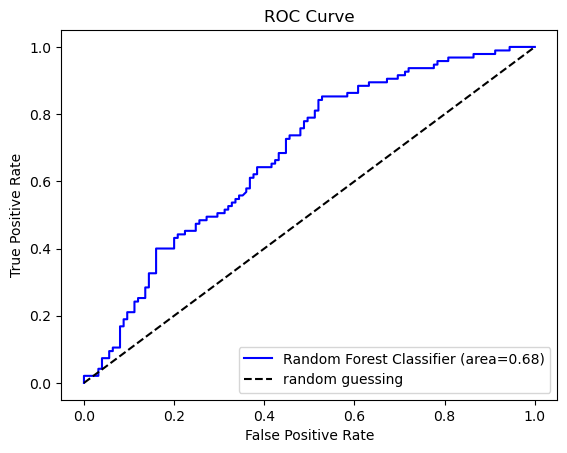

In [138]:
from sklearn.metrics import roc_curve, roc_auc_score
from matplotlib import pyplot as plt
from matplotlib import pyplot as plt

plt.plot(fpr, tpr, color='blue', label='Random Forest Classifier (area=%0.2f)' % auc)
plt.plot([0, 1], [0, 1], 'k--', label='random guessing')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.show()

## ROC curve for Training data

In [95]:
from sklearn.metrics import roc_curve,roc_auc_score
from matplotlib import pyplot as plt


In [84]:
proba = logistc_model.predict_proba(X_train)
proba

array([[7.06877042e-01, 2.93122958e-01],
       [2.64655817e-01, 7.35344183e-01],
       [4.04452938e-01, 5.95547062e-01],
       ...,
       [3.96695534e-01, 6.03304466e-01],
       [3.18651616e-01, 6.81348384e-01],
       [1.00000000e+00, 1.82875319e-10]])

In [98]:
proba = logistc_model.predict_proba(X_train)[:,1]



In [102]:
# Generate the ROC curve
fpr, tpr, thresholds = roc_curve(y_train, y_train_pred)

In [113]:
# Generate the Random guessing line
auc = roc_auc_score(y_train, y_train_pred)

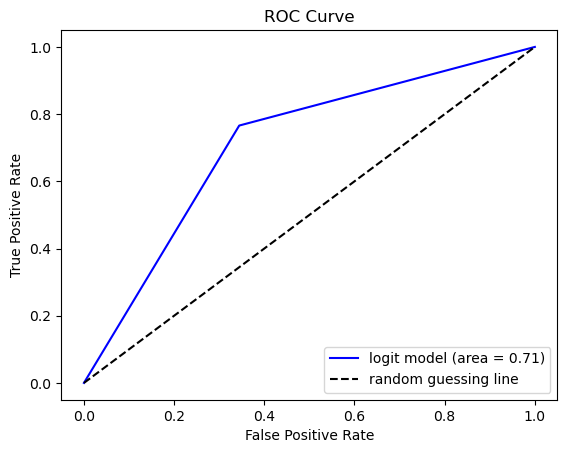

In [142]:
# plt.plot(fpr, tpr, colr='red', label='logit model ( area=%0.2f)'%auc)
plt.plot(fpr, tpr, color='blue', label='logit model (area = %0.2f)' %auc)
# plt.plot(fpr, tpr, color='blue', label=f'logit model (area = {auc:.2f})')
plt.plot([0,1], [0,1],'k--',label='random guessing line')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.show()

In [50]:
accuracy_score(y_test, y_tes)

0.6818181818181818

In [25]:
y

0       0
1       1
2       1
3       0
4       1
       ..
1334    1
1336    0
1337    1
1338    0
1339    1
Name: ATTORNEY, Length: 1096, dtype: int64

## Model Deployment

In [26]:
from pickle import dump

In [27]:
dump(logistc_model,open("claimans.pkl", "wb"))